In [1]:
from glob import glob
import sys
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
from astrometry.util.fits import fits_table, merge_tables

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('py_files'), '..')))
from py_files import brick_DCR
# forced = fits.open('/pscratch/sd/n/nelfalou/fw-test/forced-brickwise-0292p045.fits')[1].data

In [2]:
# [EDITED 2026-10-12] data come from the combined per-slice files (slurm/combine_catalogue.py)
EPOCH_DEGREES = ['000', '008', '016', '024', '032', '040', '048', '056']   # 8 slices spread over RA 0-63 (per-epoch data: ~8M rows per slice)
PLOTS = '../writeup/plots/'
from py_files import pm_analysis as pma
from py_files import plot_style as ps
ps.apply()

In [3]:
# [EDITED 2026-10-12] Gaia-star epochs (F) and Gaia-star catalogue rows (T)
F, T = pma.load_gaia_epochs(EPOCH_DEGREES)
len(F), len(T)

(77582159, 3161409)

In [4]:
crpixes = {'S1': (2151.2, 14826.0),
 'S2': (2151.2, 10566.67),
 'S3': (2151.2, 6307.333),
 'N1': (-103.2001, 14826.0),
 'N2': (-103.2001, 10566.67),
 'N3': (-103.2001, 6307.333),
 'S8': (4405.6, 12696.33),
 'S9': (4405.6, 8437.0),
 'S14': (6660.0, 12696.33),
 'S15': (6660.0, 8437.0),
 'S20': (8914.4, 10566.67),
 'S25': (11168.8, 8437.0),
 'N8': (-2357.6, 12696.33),
 'N9': (-2357.6, 8437.0),
 'N14': (-4612.0, 12696.33),
 'N15': (-4612.0, 8437.0),
 'N20': (-6866.4, 10566.67),
 'N25': (-9120.8, 8437.0),
 'S10': (4405.6, 4177.667),
 'S11': (4405.6, -81.66665),
 'S12': (4405.6, -4341.0),
 'S13': (4405.6, -8600.334),
 'S18': (6660.0, -4341.0),
 'S19': (6660.0, -8600.334),
 'S16': (6660.0, 4177.667),
 'S17': (6660.0, -81.66665),
 'S21': (8914.4, 6307.333),
 'S22': (8914.4, 2048.0),
 'S23': (8914.4, -2211.333),
 'S24': (8914.4, -6470.667),
 'S26': (11168.8, 4177.667),
 'S27': (11168.8, -81.66665),
 'S28': (11168.8, -4341.0),
 'S29': (13423.2, 6307.333),
 'S30': (13423.2, 2048.0),
 'S31': (13423.2, -2211.333),
 'N4': (-103.2001, 2048.0),
 'N5': (-103.2001, -2211.333),
 'N6': (-103.2001, -6470.667),
 'N7': (-103.2001, -10730.0),
 'S4': (2151.2, 2048.0),
 'S5': (2151.2, -2211.333),
 'S6': (2151.2, -6470.667),
 'S7': (2151.2, -10730.0),
 'N10': (-2357.6, 4177.667),
 'N11': (-2357.6, -81.66665),
 'N12': (-2357.6, -4341.0),
 'N13': (-2357.6, -8600.334),
 'N18': (-4612.0, -4341.0),
 'N19': (-4612.0, -8600.334),
 'N16': (-4612.0, 4177.667),
 'N17': (-4612.0, -81.66665),
 'N21': (-6866.4, 6307.333),
 'N22': (-6866.4, 2048.0),
 'N23': (-6866.4, -2211.333),
 'N24': (-6866.4, -6470.667),
 'N26': (-9120.8, 4177.667),
 'N27': (-9120.8, -81.66665),
 'N28': (-9120.8, -4341.0),
 'N29': (-11375.2, 6307.333),
 'N30': (-11375.2, 2048.0),
 'N31': (-11375.2, -2211.333),
 'FS1': (11168.8, -8600.334),
 'FS2': (13423.2, -6470.667),
 'FS3': (15677.6, -81.6666),
 'FS4': (15677.6, 2129.667),
 'FN1': (-9120.8, -8600.334),
 'FN2': (-11375.2, -6470.667),
 'FN3': (-13629.6, -81.6666),
 'FN4': (-13629.6, 2129.667)}

In [5]:
# [EDITED 2026-10-12] drop epochs whose star was cut from T (t_index -1 used to pick up the last row of T)
T.cut(T.ref_cat == 'GE')
T.cut((T.flux_g > 0) * (T.flux_i > 0))
objmap = dict([((bid,oid),i) for i,(bid,oid) in enumerate(zip(T.brickid, T.objid))])
F.t_index = np.array([objmap.get((bid,oid), -1) for bid,oid in zip(F.brickid, F.objid)])
F.cut(F.t_index >= 0)

# F.gaia_pmra = T.pmra[F.t_index]
# F.gaia_pmdec = T.pmdec[F.t_index]
# F.gaia_pmra_ivar = T.pmra_ivar[F.t_index]
# F.gaia_pmdec_ivar = T.pmdec_ivar[F.t_index]
F.gaia_g = T.gaia_phot_g_mean_mag[F.t_index]
F.gaia_bp = T.gaia_phot_bp_mean_mag[F.t_index]
F.gaia_rp = T.gaia_phot_rp_mean_mag[F.t_index]
F.flux_g = T.flux_g[F.t_index]
# F.flux_r = T.flux_r[F.t_index]
F.flux_i = T.flux_i[F.t_index]
# F.flux_z = T.flux_z[F.t_index]
T.color = -2.5 * (np.log10(T.flux_g / T.flux_i))
F.color = T.color[F.t_index]

p = np.array([crpixes[c] for c in F.ccdname])
F.fpx = F.rm_full_fit_x - p[:,0]
F.fpy = F.rm_full_fit_y - p[:,1]

ux = F.fpx / np.hypot(F.fpx, F.fpy)
uy = F.fpy / np.hypot(F.fpx, F.fpy)
F.dr = (F.rm_full_fit_x - F.x) * ux + (F.rm_full_fit_y - F.y) * uy

In [6]:
# Define cuts I1,I2,I3 for the three color bins.
filt = 'r'
Iok = np.flatnonzero(F.filter == filt)

# pcolors = np.percentile(T.color[F.t_index[Iok]], [1, 33, 66, 99])
pcolors = [0, 1, 2.3, 3.5] # TODO
I1 = np.flatnonzero((F.filter == filt) * (F.color > pcolors[0]) * (F.color < pcolors[1]))
I2 = np.flatnonzero((F.filter == filt) * (F.color > pcolors[1]) * (F.color < pcolors[2]))
I3 = np.flatnonzero((F.filter == filt) * (F.color > pcolors[2]) * (F.color < pcolors[3]))
len(I1), len(I2), len(I3)

(7094255, 5758904, 4177044)

In [7]:
CCD_annotated = fits_table('/global/cfs/cdirs/cosmo/work/users/dstn/forced-motions-dr10/survey-ccds-decam-dr10-bprp-kd.fits')
BPRP_MAP = dict([((expnum, ccdname), bprp) for expnum,ccdname,bprp in zip(CCD_annotated.expnum, CCD_annotated.ccdname, CCD_annotated.ccdbprp)])

F.bprp = F.gaia_bp - F.gaia_rp
F.bprp_calib = np.array([BPRP_MAP[(e,c)] for e,c in zip(F.expnum, F.ccdname)])
F.gi_calib = -0.56 + 1.34 * F.bprp_calib
F.gi_color = -2.5 * (np.log10(F.flux_g / F.flux_i))
F.gi_rel = F.gi_color - F.gi_calib

In [8]:
I = np.flatnonzero((F.filter == 'r') *
                   (F.full_fit_dra_ivar != 0) *
                   (F.full_fit_x != F.x) *
                   (F.gaia_bp != 0.) *
                   (F.gaia_rp != 0.) *
                   (F.flux_g != 0) * 
                   (F.flux_i != 0) *
                   (F.dp1 != 0.))
len(I)

15689029

In [9]:
# [EDITED 2026-10-14] dp1_before computed here in arcsec: the file's dp1 column is in PIXELS, and the
# "before" panels used it next to dp1_after in arcsec (same colour scale) -- the before signal looked 3.8x too small.
F.ha = brick_DCR.hour_angle(F.ra, F.mjd + 0.5 * F.exptime / (24 * 60 * 60))
_, F.parallactic = brick_DCR.parallactic(F.dec, F.ha)

dx = F.full_fit_x - F.x
dy = F.full_fit_y - F.y
F.dp1_before = (dx * np.cos(F.parallactic) - dy * np.sin(F.parallactic)) * 0.262   # arcsec, along parallactic dir.

dx = F.dcr_full_fit_x - F.x
dy = F.dcr_full_fit_y - F.y
F.dp1_after = (dx * np.cos(F.parallactic) - dy * np.sin(F.parallactic)) * 0.262    # arcsec

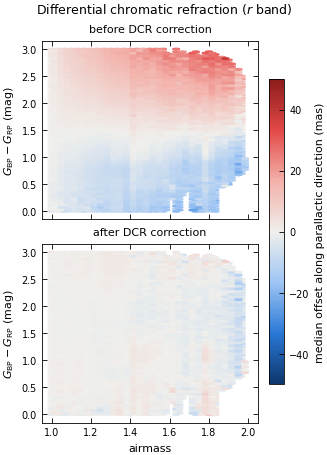

In [10]:
# [EDITED 2026-10-22] post-meeting plot changes (PLAN "PLAN AFTER DUSTIN MEETING", F)
# F2: median offset along the parallactic direction of r-band Gaia-star epochs (selection I above), vs airmass
# and Gaia BP-RP colour, before (top) and after (bottom) the DCR correction. Bins with < 100 epochs are blank.
def my_reduce(x):
    if len(x) < 100:
        return np.nan
    return np.median(x)

fig, axes = plt.subplots(2, 1, figsize=(ps.COLUMN, 4.6), sharex=True, sharey=True, constrained_layout=True)
for ax, col, title in [(axes[0], F.dp1_before, 'before DCR correction'), (axes[1], F.dp1_after, 'after DCR correction')]:
    hb = ax.hexbin(F.airmass[I], F.bprp[I], C=col[I] * 1000, reduce_C_function=my_reduce, vmin=-50, vmax=50,
                   extent=(1.0, 2.0, 0., 3.0), gridsize=(30, 60), cmap=ps.DIVERGING)
    ax.set_title(title)
    ax.set_ylabel(r'$G_{\rm BP}-G_{\rm RP}$ (mag)')
axes[1].set_xlabel('airmass')
fig.colorbar(hb, ax=axes, shrink=0.8, label='median offset along parallactic direction (mas)')
fig.suptitle('Differential chromatic refraction ($r$ band)')
plt.savefig(PLOTS + 'dcr_before_after.png', dpi=300)


Text(0.5, 1.0, 'after DCR correction')

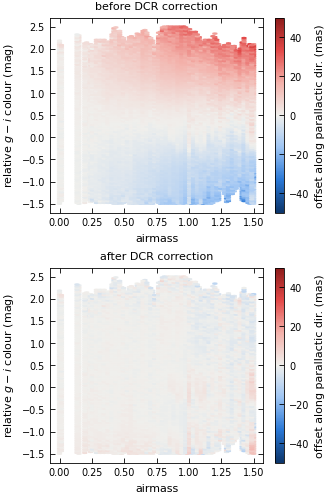

In [11]:
# [EDITED 2026-10-14] shared plot style (py_files/plot_style.py): print-size figure, colour-blind-safe colours
# [EDITED 2026-10-14] colour scale in mas (+-50): DCR offsets are tens of mas; +-0.3 arcsec washed them out
# [EDITED 2026-10-14] "before" panel now uses dp1_before (arcsec), not the pixel-unit dp1 column
plt.figure(figsize=(ps.COLUMN, 5.0), constrained_layout=True)
plt.subplot(2, 1, 1)
plt.hexbin(np.sqrt(F.airmass[I]**2 - 1), F.gi_rel[I], C=F.dp1_before[I] * 1000, reduce_C_function=my_reduce, vmin=-50, vmax=50,
          extent=(0, 1.5, -1.5, 2.5), gridsize=(50,100), cmap=ps.DIVERGING);
plt.xlabel('airmass')
plt.ylabel('relative $g-i$ colour (mag)')
cb = plt.colorbar()
cb.set_label('offset along parallactic dir. (mas)')
plt.title("before DCR correction")

plt.subplot(2, 1, 2)
plt.hexbin(np.sqrt(F.airmass[I]**2 - 1), F.gi_rel[I], C=F.dp1_after[I] * 1000, reduce_C_function=my_reduce, vmin=-50, vmax=50,
          extent=(0, 1.5, -1.5, 2.5), gridsize=(50,100), cmap=ps.DIVERGING);
plt.xlabel('airmass')
plt.ylabel('relative $g-i$ colour (mag)')
cb = plt.colorbar()
cb.set_label('offset along parallactic dir. (mas)')
plt.title("after DCR correction")
# plt.savefig('dcr3.png')

{
 "g": {
  "c_break": 0.05,
  "a": 3.517047486259896,
  "b_blue": 39.74743059232909,
  "b_red": 25.105335256648317
 },
 "r": {
  "c_break": 0.7,
  "a": 3.291904741083401,
  "b_blue": 7.898843328802415,
  "b_red": 13.108582940580412
 },
 "i": {
  "c_break": 0.5,
  "a": -0.13369514725142276,
  "b_blue": 3.438184370984691,
  "b_red": 6.334902494243137
 },
 "z": {
  "c_break": -0.1,
  "a": -0.8198309137260379,
  "b_blue": 0.9437288059303737,
  "b_red": 1.5383279063453696
 }
}


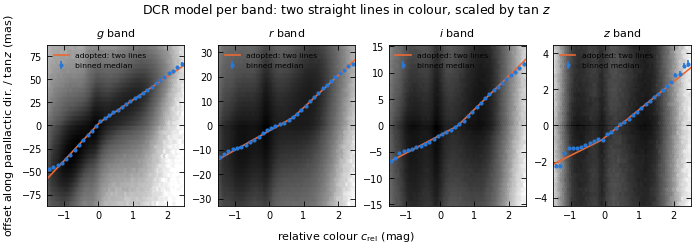

In [12]:
# [EDITED 2026-10-23] A3: F3 now shows the adopted two-line DCR model
# F3: the adopted DCR model per band (since 2026-10-23): offset along the parallactic direction
# dp1 = tan z * (a + b_blue min(c - c_b, 0) + b_red max(c - c_b, 0)), c = c_rel clipped to [-1.5, 2.5],
# c_rel = (g-i) - (g-i)_ref of the CCD, tan z = sqrt(X^2 - 1). Coefficients from run/dcr-polyfit.ipynb (all 000-063
# bricks) in py_files/dcr_model_twoline.json. Shown as dp1 / tan z against c_rel, so the model is the broken line itself.
# Data: high-S/N epochs (sigma < 10 mas) before the DCR correction, tan z > 0.3 (dividing by small tan z only adds noise).
bands = ['g', 'r', 'i', 'z']
import json
cbins = np.linspace(-1.5, 2.5, 33)
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.5), sharex=True, constrained_layout=True)
for ax, b in zip(axes, bands):
    tz = np.sqrt(np.maximum(F.airmass**2 - 1, 0))
    J = np.flatnonzero((F.filter == b) * (F.full_fit_dra_ivar > 1e4) * (tz > 0.3) *
                       np.isfinite(F.gi_rel) * (np.abs(F.gi_rel) < 3) * (F.full_fit_x != F.x))
    cc = F.gi_rel[J]
    yy = F.dp1_before[J] * 1000. / tz[J]   # mas per unit tan z
    idx = np.digitize(cc, cbins)
    xc, ym, ye = [], [], []
    for k in range(1, len(cbins)):
        m = idx == k
        if m.sum() < 30:
            continue
        xc.append(np.median(cc[m])); ym.append(np.median(yy[m]))
        ye.append(1.2533 * 1.4826 * np.median(np.abs(yy[m] - np.median(yy[m]))) / np.sqrt(m.sum()))
    xc, ym, ye = map(np.array, (xc, ym, ye))
    lim = 1.3 * np.nanmax(np.abs(ym)) if len(ym) else 50
    ax.hexbin(cc, yy, gridsize=60, extent=(-1.5, 2.5, -lim, lim), bins='log', cmap=ps.DENSITY, mincnt=1)
    ax.errorbar(xc, ym, ye, fmt='o', ms=2, color=ps.SERIES[0], label='binned median')
    xl = np.linspace(-1.5, 2.5, 200)
    ax.plot(xl, brick_DCR.dcr_shift_mas(np.full(len(xl), b), xl, np.ones(len(xl))), color=ps.SERIES[1], ls='-',
            label='adopted: two lines')
    ax.set_xlim(-1.5, 2.5); ax.set_ylim(-lim, lim)
    ax.set_title(f'${b}$ band')
    ax.legend(fontsize=5.5, loc='upper left')
axes[0].set_ylabel(r'offset along parallactic dir. / $\tan z$ (mas)')
fig.supxlabel(r'relative colour $c_{\rm rel}$ (mag)', fontsize=8)
fig.suptitle('DCR model per band: two straight lines in colour, scaled by tan $z$')
plt.savefig(PLOTS + 'dcr_amplitude_fit.pdf')
print(json.dumps(brick_DCR.DCR_MODEL['bands'], indent=1))


Text(0.5, 1.0, 'after DCR correction')

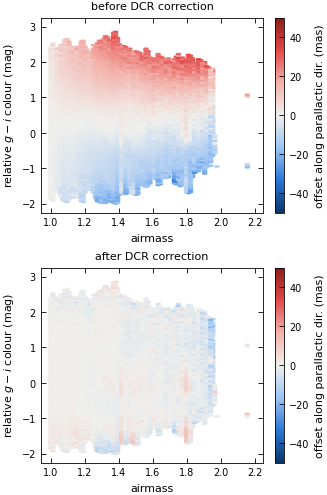

In [13]:
# [EDITED 2026-10-14] shared plot style (py_files/plot_style.py): print-size figure, colour-blind-safe colours
# [EDITED 2026-10-14] colour scale in mas (+-50): DCR offsets are tens of mas; +-0.3 arcsec washed them out
# [EDITED 2026-10-14] "before" panel now uses dp1_before (arcsec), not the pixel-unit dp1 column
plt.figure(figsize=(ps.COLUMN, 5.0), constrained_layout=True)
plt.subplot(2, 1, 1)
plt.hexbin(F.airmass[I], F.gi_rel[I], C=F.dp1_before[I] * 1000, reduce_C_function=my_reduce, vmin=-50, vmax=50,
          gridsize=(50,100), cmap=ps.DIVERGING);
plt.xlabel('airmass')
plt.ylabel('relative $g-i$ colour (mag)')
cb = plt.colorbar()
cb.set_label('offset along parallactic dir. (mas)')
plt.title("before DCR correction")

plt.subplot(2, 1, 2)
plt.hexbin(F.airmass[I], F.gi_rel[I], C=F.dp1_after[I] * 1000, reduce_C_function=my_reduce, vmin=-50, vmax=50,
          gridsize=(50,100), cmap=ps.DIVERGING);
plt.xlabel('airmass')
plt.ylabel('relative $g-i$ colour (mag)')
cb = plt.colorbar()
cb.set_label('offset along parallactic dir. (mas)')
plt.title("after DCR correction")
# plt.savefig('dcr3.png')